<a href="https://colab.research.google.com/github/faiq191/244107020214-machine-learning/blob/main/JS07/JS07_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Load Dataset & Scatter Plot (Avg_Credit_Limit vs Total_Credit_Cards)

   Sl_No  Customer Key  Avg_Credit_Limit  Total_Credit_Cards  \
0      1         87073            100000                   2   
1      2         38414             50000                   3   
2      3         17341             50000                   7   
3      4         40496             30000                   5   
4      5         47437            100000                   6   

   Total_visits_bank  Total_visits_online  Total_calls_made  
0                  1                    1                 0  
1                  0                   10                 9  
2                  1                    3                 4  
3                  1                    1                 4  
4                  0                   12                 3  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    i

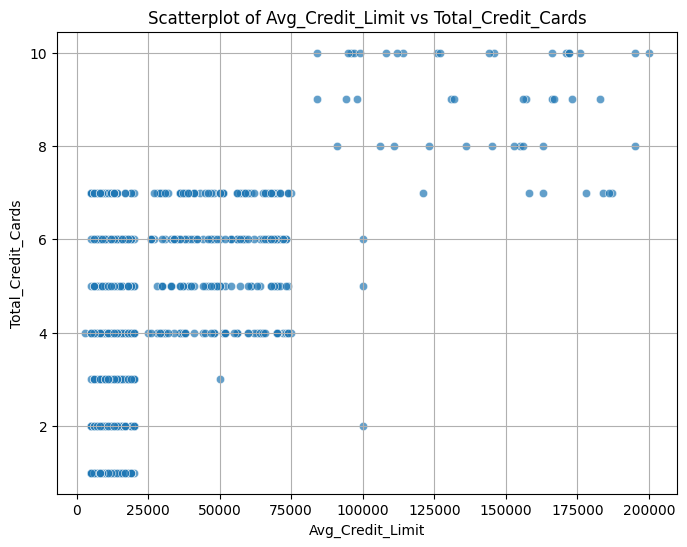

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset (Pastikan file CC_Customer_Dataset.csv sudah di-upload ke Colab)
df = pd.read_csv('CC_Customer_Dataset.csv')

# Display basic info
print(df.head())
print(df.info())

# Create scatterplot
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='Avg_Credit_Limit', y='Total_Credit_Cards', alpha=0.7)
plt.title('Scatterplot of Avg_Credit_Limit vs Total_Credit_Cards')
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.grid(True)
plt.show()

2. K-Means Clustering & Elbow Method

/tmp/ipykernel_1288/2955102442.py:21: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "bx-" (-> marker='x'). The keyword argument will take precedence.
  plt.plot(K, sse, 'bx-', marker='o')


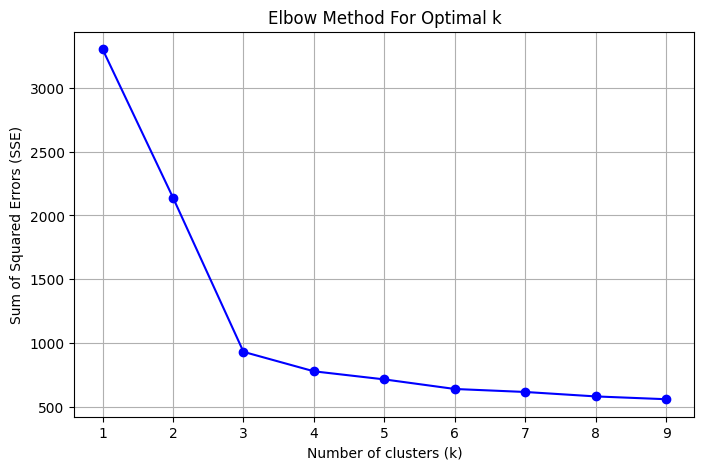

In [2]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Select usable variables for clustering (drop ID columns)
X_cluster = df.drop(columns=['Sl_No', 'Customer Key'])

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

# Find optimal k using Elbow Method
sse = []
K = range(1, 10)
for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init='auto')
    kmeans.fit(X_scaled)
    sse.append(kmeans.inertia_)

# Plot Elbow Line Chart
plt.figure(figsize=(8, 5))
plt.plot(K, sse, 'bx-', marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Sum of Squared Errors (SSE)')
plt.title('Elbow Method For Optimal k')
plt.grid(True)
plt.show()

3. K-Means Clustering Scatter Plot (k = 3)

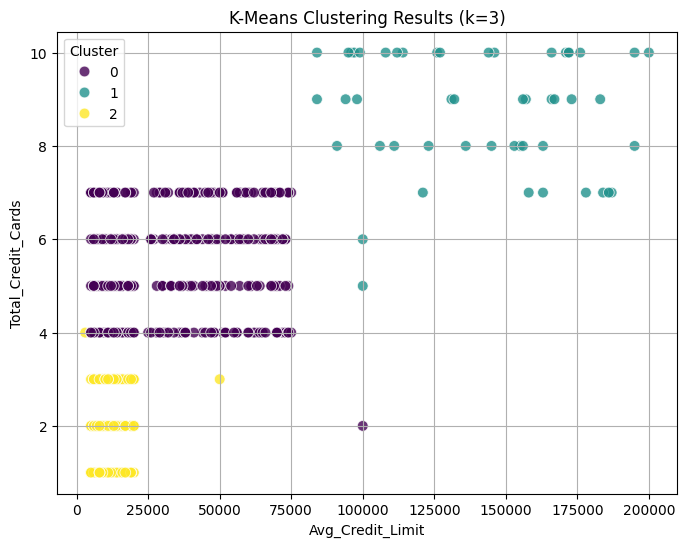

In [3]:
# Fit K-Means with optimal k = 3
kmeans_optimal = KMeans(n_clusters=3, random_state=42, n_init='auto')
df['Cluster_KMeans'] = kmeans_optimal.fit_predict(X_scaled)

# Plot K-Means Clustering Result
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x='Avg_Credit_Limit',
    y='Total_Credit_Cards',
    hue='Cluster_KMeans',
    palette='viridis',
    alpha=0.8,
    s=60
)
plt.title('K-Means Clustering Results (k=3)')
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.legend(title='Cluster')
plt.grid(True)
plt.show()

4. DBSCAN Clustering Model & Evaluation (Silhouette Score & DBI)

In [4]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Construct DBSCAN model using all usable variables (X_scaled)
# You can tune eps and min_samples based on your data density
dbscan = DBSCAN(eps=0.8, min_samples=5)
df['Cluster_DBSCAN'] = dbscan.fit_predict(X_scaled)

# Filter out noise points (labeled as -1) for evaluation metrics if needed,
# or evaluate across all assigned labels depending on preference.
# Here we evaluate directly on labels generated:
labels = dbscan.labels_

# Calculate Silhouette Score and Davies-Bouldin Index (DBI)
# Note: Silhouette and DBI require at least 2 valid clusters (excluding noise -1 if applicable, or overall)
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)

print(f'Estimated number of clusters: {n_clusters_}')
print(f'Estimated number of noise points: {n_noise_}')

if n_clusters_ > 1:
    sil_score = silhouette_score(X_scaled, labels)
    dbi_score = davies_bouldin_score(X_scaled, labels)
    print(f'Silhouette Score: {sil_score:.4f}')
    print(f'Davies-Bouldin Index (DBI): {dbi_score:.4f}')
else:
    print("DBSCAN produced 1 or 0 clusters. Adjust eps or min_samples.")

Estimated number of clusters: 2
Estimated number of noise points: 44
Silhouette Score: 0.4895
Davies-Bouldin Index (DBI): 2.0349
